In [27]:
!pip install xgboost

In [48]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBRegressor
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns # Grafiği daha şık yapmak için
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [49]:
df=pd.read_csv("emissions_high_granularity.csv")
df.head()

,year,parent_entity,parent_type,reporting_entity,commodity,production_value,production_unit,product_emissions_MtCO2,flaring_emissions_MtCO2,venting_emissions_MtCO2,own_fuel_use_emissions_MtCO2,fugitive_methane_emissions_MtCO2e,fugitive_methane_emissions_MtCH4,total_operational_emissions_MtCO2e,total_emissions_MtCO2e,source
0,1962,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,0.9125,Million bbl/yr,0.338928,0.005404,0.001299,0.0,0.018254,0.000652,0.024957,0.363885,Abu Dhabi National Oil Company Annual Report 1...
1,1963,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,1.8250,Million bbl/yr,0.677855,0.010808,0.002598,0.0,0.036508,0.001304,0.049914,0.727770,Abu Dhabi National Oil Company Annual Report 1...
2,1964,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,7.3000,Million bbl/yr,2.711422,0.043233,0.010392,0.0,0.146033,0.005215,0.199657,2.911079,Abu Dhabi National Oil Company Annual Report 1...
3,1965,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,10.9500,Million bbl/yr,4.067132,0.064849,0.015588,0.0,0.219049,0.007823,0.299486,4.366618,Abu Dhabi National Oil Company Annual Report 1...
4,1966,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,13.5050,Million bbl/yr,5.016130,0.079980,0.019225,0.0,0.270160,0.009649,0.369366,5.385495,Abu Dhabi National Oil Company Annual Report 1...


In [50]:
df.isnull().sum() # eksik değerleri listeledik

year                                  0
parent_entity                         0
parent_type                           0
reporting_entity                      0
commodity                             0
production_value                      0
production_unit                       0
product_emissions_MtCO2               0
flaring_emissions_MtCO2               0
venting_emissions_MtCO2               0
own_fuel_use_emissions_MtCO2          0
fugitive_methane_emissions_MtCO2e     0
fugitive_methane_emissions_MtCH4      0
total_operational_emissions_MtCO2e    0
total_emissions_MtCO2e                0
source                                0
dtype: int64

In [51]:
df=df.fillna(0) #boşluk varsa diye her ihtimale karşı yaptık.

In [52]:
df.describe() # geneler değerleri görelim diye yaptık.

,year,production_value,product_emissions_MtCO2,flaring_emissions_MtCO2,venting_emissions_MtCO2,own_fuel_use_emissions_MtCO2,fugitive_methane_emissions_MtCO2e,fugitive_methane_emissions_MtCH4,total_operational_emissions_MtCO2e,total_emissions_MtCO2e
count,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000,15797.000000
mean,1985.827942,327.879634,79.391514,0.517226,0.462462,0.688676,8.884203,0.317293,10.552566,89.944080
std,28.664256,1188.625001,261.984080,1.783744,1.804575,3.564171,31.358244,1.119937,34.790479,292.843491
min,1854.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1970.000000,11.800000,5.996490,0.000000,0.000000,0.000000,0.607068,0.021681,0.751999,7.208860
50%,1993.000000,59.970871,21.502409,0.015913,0.045247,0.000000,2.351126,0.083969,2.869611,25.116721
75%,2007.000000,246.375000,62.191954,0.197253,0.329719,0.162415,7.401655,0.264345,8.965620,72.255340
max,2022.000000,27192.000000,7769.222235,27.026872,41.458662,83.203465,877.683714,31.345847,877.683714,8646.905949


In [53]:
# parent_type ve commodity sütunları için numara atayalım ynai label encoder kullanalım.
lbl_encoder_commodity=LabelEncoder()
df['commodity_encoded']= lbl_encoder_commodity.fit_transform(df['commodity'])

lbl_encoder_parent=LabelEncoder()
df['parent_type_encoded']=lbl_encoder_parent.fit_transform(df['parent_type'])

print(df[['commodity','commodity_encoded','parent_type','parent_type_encoded']].head())

   commodity  commodity_encoded         parent_type  parent_type_encoded
0  Oil & NGL                  6  State-owned Entity                    2
1  Oil & NGL                  6  State-owned Entity                    2
2  Oil & NGL                  6  State-owned Entity                    2
3  Oil & NGL                  6  State-owned Entity                    2
4  Oil & NGL                  6  State-owned Entity                    2


In [54]:
# regresyon için girdi ve çıktıyı belirleyelim.
X = df[['year','production_value','commodity_encoded','parent_type_encoded']] # X -girdiler

y= df['total_emissions_MtCO2e'] # y-hedef

print("Girdiler:",X.shape)
print("Hedef:",y.shape)

Girdiler: (15797, 4)
Hedef: (15797,)


In [55]:
# şimde de modelin ezberini ölçmek için modeli %80 eğitim ve %20 test diye iki parçaya ayıralım.
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state =142)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(12637, 4)
(12637,)
(3160, 4)
(3160,)


In [56]:
#Veriler hem sayısal (üretim) hem kategorik (kömür/gaz). XGBoost bu tür karışık verilerde en iyi sonucu verir ve hata yapma oranı düşüktür.
regressor=XGBRegressor(random_state=142) #elimizdeki sayısal verilerle tahmin yaptık.
regressor.fit(X_train,y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [57]:
# başarı ölçümü için bu projeye en uygun yöntem R-Kare skoru olurmuş.
y_pred = regressor.predict(X_test)
r2= r2_score(y_true=y_test,y_pred=y_pred)
print("R2 Socre: %{:10.2f}".format(r2*100))


R2 Socre: %     98.72


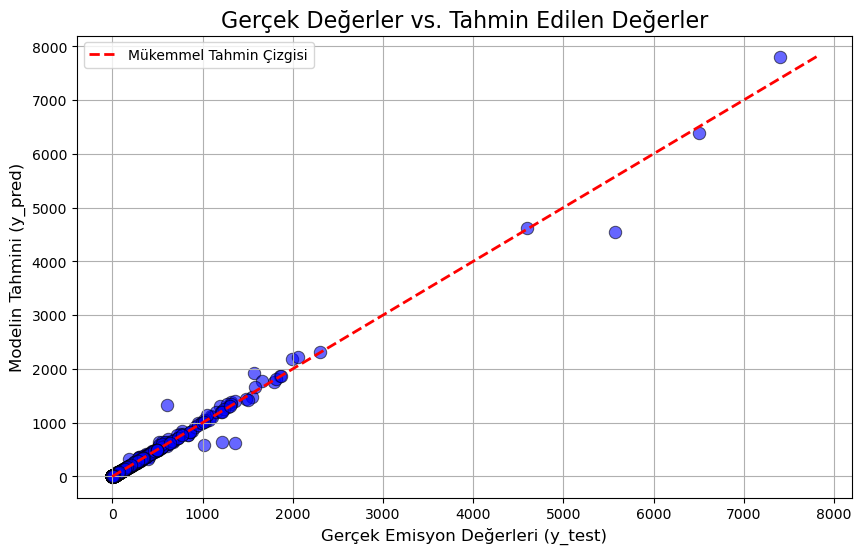

In [58]:
# R2 scoresini grafiğe dökelim
plt.figure(figsize=(10,6))

sns.scatterplot(x=y_test,y=y_pred,color='blue',alpha=0.6,s=80,edgecolor='black')

min_val=min(y_test.min(),y_pred.min())
max_val=max(y_test.max(),y_pred.max())
plt.plot([min_val,max_val],[min_val, max_val], color='red', linestyle='--', linewidth=2, label='Mükemmel Tahmin Çizgisi')

plt.title('Gerçek Değerler vs. Tahmin Edilen Değerler', fontsize=16)
plt.xlabel('Gerçek Emisyon Değerleri (y_test)', fontsize=12)
plt.ylabel('Modelin Tahmini (y_pred)', fontsize=12)
plt.legend()
plt.grid(True) # Izgara ekle ki okuması kolay olsun

# Grafiği Göster
plt.show()


In [59]:
print(df.columns)

Index(['year', 'parent_entity', 'parent_type', 'reporting_entity', 'commodity',
       'production_value', 'production_unit', 'product_emissions_MtCO2',
       'flaring_emissions_MtCO2', 'venting_emissions_MtCO2',
       'own_fuel_use_emissions_MtCO2', 'fugitive_methane_emissions_MtCO2e',
       'fugitive_methane_emissions_MtCH4',
       'total_operational_emissions_MtCO2e', 'total_emissions_MtCO2e',
       'source', 'commodity_encoded', 'parent_type_encoded'],
      dtype='object')


In [60]:
# Müşteri Segmentasyonu yapma zamanı, şirketlerin kirlik karakterini bulalım
secilen_sutunlar=[
    'flaring_emissions_MtCO2', #Gaz yakma
    'venting_emissions_MtCO2',  # Havaya salma
    'fugitive_methane_emissions_MtCO2e',  # Kaçak metan (CO2 eşdeğeri)
    'own_fuel_use_emissions_MtCO2' # Kendi yakıt kullanımı
]
X_cluster=df[secilen_sutunlar]

In [61]:
# Normalizasyonn yapalım
scaler=StandardScaler()
X_scaled= scaler.fit_transform(X_cluster)
print("veri ölçeklendi")

veri ölçeklendi


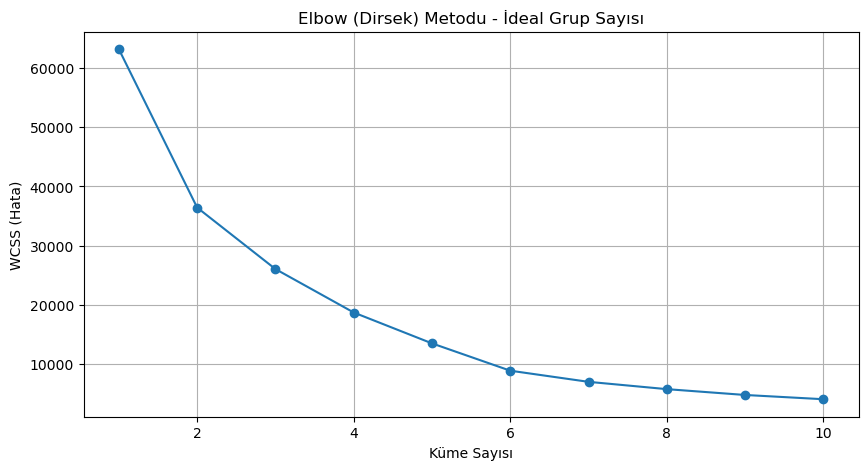

In [62]:
# doğru k değeri için elbow yöntemi yapalım.
wcss=[]
kume_sayisi_listesi=range(1,11)
for i in kume_sayisi_listesi:
    kmeans=KMeans(n_clusters=i, init='k-means++',max_iter=300,n_init=10,random_state=0)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)


plt.figure(figsize=(10,5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow (Dirsek) Metodu - İdeal Grup Sayısı')
plt.xlabel('Küme Sayısı')
plt.ylabel('WCSS (Hata)')
plt.grid(True)
plt.show()

In [63]:
# Modeli çalıştıralım
kume_sayisi=3 # üstteki grafikte k degeri=2 kırılma 2 de ama bu proje için 2 grup az olur 3 yapalım biz bunu
kmeans = KMeans(n_clusters=kume_sayisi, init='k-means++', random_state=42)

y_kmeans = kmeans.fit_transform(X_scaled) # Burada fit_predict de kullanılabilir
y_kmeans = kmeans.predict(X_scaled)

df['Kirlilik_Grubu'] = y_kmeans

In [64]:
analiz = df.groupby('Kirlilik_Grubu')[secilen_sutunlar].mean()
print(analiz.round(2))

print("\n--Grptaki Şirketler--")
print(df['Kirlilik_Grubu'].value_counts())

                flaring_emissions_MtCO2  venting_emissions_MtCO2  \
Kirlilik_Grubu                                                     
0                                  0.51                     0.38   
1                                  1.72                    28.25   
2                                  0.00                     0.00   

                fugitive_methane_emissions_MtCO2e  \
Kirlilik_Grubu                                      
0                                            7.29   
1                                          273.81   
2                                          624.67   

                own_fuel_use_emissions_MtCO2  
Kirlilik_Grubu                                
0                                       0.52  
1                                      56.69  
2                                       0.00  

--Grptaki Şirketler--
Kirlilik_Grubu
0    15729
1       48
2       20
Name: count, dtype: int64


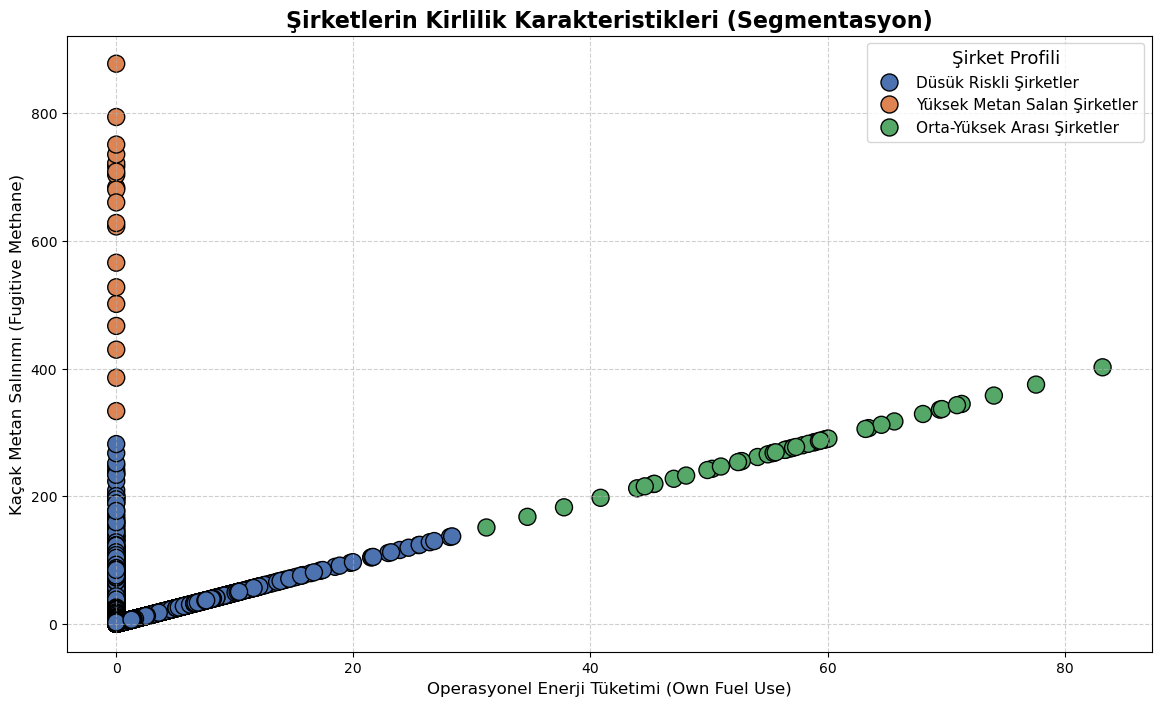

Dosya başarıyla kaydedildi!


In [65]:
# Görselleştirme yapalım
grup_isimleri ={
    0:'Düsük Riskli Şirketler',
    1:'Orta-Yüksek Arası Şirketler',
    2:'Yüksek Metan Salan Şirketler'
}
df['Segment_Tanimi']=df['Kirlilik_Grubu'].map(grup_isimleri)

plt.figure(figsize=(14,8))
sns.scatterplot(
    data=df,
    x='own_fuel_use_emissions_MtCO2',
    y='fugitive_methane_emissions_MtCO2e',
    hue='Segment_Tanimi',
    palette='deep',
    s=150,
    edgecolor='black'
)


plt.title('Şirketlerin Kirlilik Karakteristikleri (Segmentasyon)', fontsize=16, fontweight='bold')
plt.xlabel('Operasyonel Enerji Tüketimi (Own Fuel Use)', fontsize=12)
plt.ylabel('Kaçak Metan Salınımı (Fugitive Methane)', fontsize=12)
plt.legend(title='Şirket Profili', title_fontsize='13', fontsize='11', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
    
plt.show()

df.to_csv('Sirket_Segmentasyon_Sonuclari.csv', index=False)
print("Dosya başarıyla kaydedildi!")

In [66]:
from sklearn.metrics import silhouette_score

results = {}
kume_sayisi_listesi = range(2, 10)
for i in kume_sayisi_listesi :
    kmeans = KMeans(n_clusters = i, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
    kmeans.fit(X_scaled)
    predictions = kmeans.predict(X_scaled)
    results[i] = silhouette_score(X_scaled, predictions)
    print("k {} için {}".format(i, results[i]))

k 2 için 0.9549298859617376
k 3 için 0.837064294901194
k 4 için 0.8172794860031558
k 5 için 0.7981510835030436
k 6 için 0.7888714054280133
k 7 için 0.796728604931693
k 8 için 0.719164046172202
k 9 için 0.7249630109146391


In [67]:
# Modeli çalıştıralım
kume_sayisi=2 # üstteki grafikte k degeri=2 kırılma 2 de ama bu proje için 2 grup az olur 3 yapalım biz bunu
kmeans = KMeans(n_clusters=kume_sayisi, init='k-means++', random_state=42)

y_kmeans = kmeans.fit_transform(X_scaled) # Burada fit_predict de kullanılabilir
y_kmeans = kmeans.predict(X_scaled)

df['Kirlilik_Grubu'] = y_kmeans
df.head()

,year,parent_entity,parent_type,reporting_entity,commodity,production_value,production_unit,product_emissions_MtCO2,flaring_emissions_MtCO2,venting_emissions_MtCO2,own_fuel_use_emissions_MtCO2,fugitive_methane_emissions_MtCO2e,fugitive_methane_emissions_MtCH4,total_operational_emissions_MtCO2e,total_emissions_MtCO2e,source,commodity_encoded,parent_type_encoded,Kirlilik_Grubu,Segment_Tanimi
0,1962,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,0.9125,Million bbl/yr,0.338928,0.005404,0.001299,0.0,0.018254,0.000652,0.024957,0.363885,Abu Dhabi National Oil Company Annual Report 1...,6,2,0,Düsük Riskli Şirketler
1,1963,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,1.8250,Million bbl/yr,0.677855,0.010808,0.002598,0.0,0.036508,0.001304,0.049914,0.727770,Abu Dhabi National Oil Company Annual Report 1...,6,2,0,Düsük Riskli Şirketler
2,1964,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,7.3000,Million bbl/yr,2.711422,0.043233,0.010392,0.0,0.146033,0.005215,0.199657,2.911079,Abu Dhabi National Oil Company Annual Report 1...,6,2,0,Düsük Riskli Şirketler
3,1965,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,10.9500,Million bbl/yr,4.067132,0.064849,0.015588,0.0,0.219049,0.007823,0.299486,4.366618,Abu Dhabi National Oil Company Annual Report 1...,6,2,0,Düsük Riskli Şirketler
4,1966,Abu Dhabi National Oil Company,State-owned Entity,Abu Dhabi,Oil & NGL,13.5050,Million bbl/yr,5.016130,0.079980,0.019225,0.0,0.270160,0.009649,0.369366,5.385495,Abu Dhabi National Oil Company Annual Report 1...,6,2,0,Düsük Riskli Şirketler


In [70]:
kmeans.cluster_centers_

array([[-2.05194059e-03, -4.69269723e-02, -2.57496986e-02,
        -4.78879192e-02],
       [ 6.73250257e-01,  1.53969351e+01,  8.44858341e+00,
         1.57122258e+01]])

In [68]:
analiz = df.groupby('Kirlilik_Grubu')[secilen_sutunlar].mean()
print(analiz.round(2))

print("\n--Grptaki Şirketler--")
print(df['Kirlilik_Grubu'].value_counts())

                flaring_emissions_MtCO2  venting_emissions_MtCO2  \
Kirlilik_Grubu                                                     
0                                  0.51                     0.38   
1                                  1.72                    28.25   

                fugitive_methane_emissions_MtCO2e  \
Kirlilik_Grubu                                      
0                                            8.08   
1                                          273.81   

                own_fuel_use_emissions_MtCO2  
Kirlilik_Grubu                                
0                                       0.52  
1                                      56.69  

--Grptaki Şirketler--
Kirlilik_Grubu
0    15749
1       48
Name: count, dtype: int64


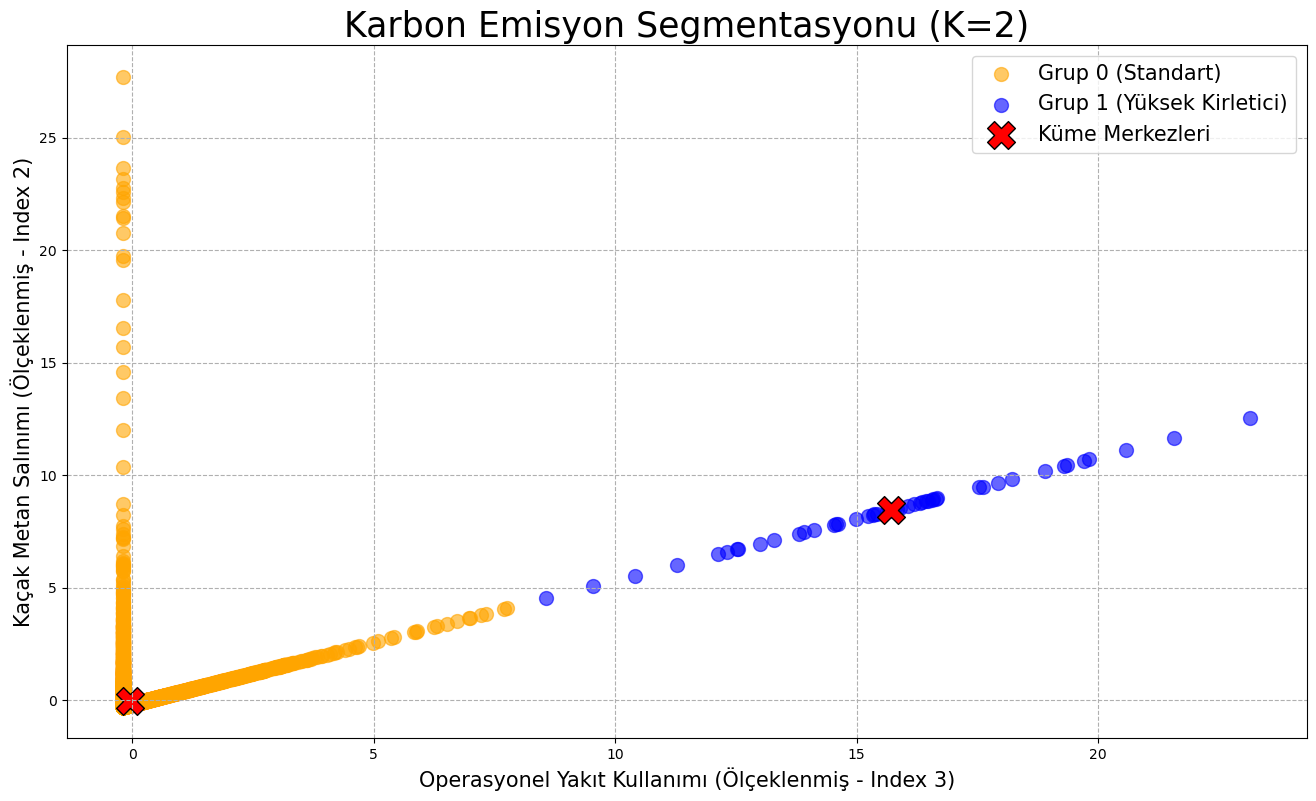

In [69]:
# kanvas genişliği
plt.figure(figsize=(16,9))
# Küme 0 (Turuncu)
# X_scaled verisinden, y_kmeans'i 0 olanların 3. ve 2. sütunlarını al
plt.scatter(X_scaled[y_kmeans == 0, 3], X_scaled[y_kmeans == 0, 2], s = 100, c = 'orange', label = 'Grup 0 (Standart)', alpha=0.6)

# Küme 1 (Mavi)
# X_scaled verisinden, y_kmeans'i 1 olanların 3. ve 2. sütunlarını al
plt.scatter(X_scaled[y_kmeans == 1, 3], X_scaled[y_kmeans == 1, 2], s = 100, c = 'blue', label = 'Grup 1 (Yüksek Kirletici)', alpha=0.6)

# (Küme 2, 3, 4 satırlarını sildik çünkü bizde yok)

# --- KÜME MERKEZLERİ (Kırmızı Noktalar) ---
# Merkezlerin de 3. ve 2. sütunlarını çizdirmeliyiz
plt.scatter(kmeans.cluster_centers_[:, 3], kmeans.cluster_centers_[:, 2], s = 400, 
            c = 'red', label = 'Küme Merkezleri', alpha=1, marker='X', edgecolor='black')

# --- BAŞLIKLAR VE ETİKETLER (BİZİM PROJEYE GÖRE) ---
plt.title('Karbon Emisyon Segmentasyonu (K=2)', fontsize = 25)
plt.xlabel('Operasyonel Yakıt Kullanımı (Ölçeklenmiş - Index 3)', fontsize = 15)
plt.ylabel('Kaçak Metan Salınımı (Ölçeklenmiş - Index 2)', fontsize = 15)
plt.legend(fontsize=15)
plt.grid(True, linestyle='--')

plt.show()